<a href="https://colab.research.google.com/github/noorhantaie94/AutoGis-Ex5/blob/main/02_sentinel2_wetland_pipeline_py.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install pystac-client rasterio geopandas scikit-learn matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25/25 [pystac-client]


1. Connecting to STAC catalog...


/usr/local/lib/python3.13/dist-packages/pystac/extensions/storage.py:724: UserWarning: Could not parse bucket/account from href. The following assets were not migrated: ['red', 'green', 'blue', 'visual', 'nir', 'swir22', 'rededge2', 'rededge3', 'rededge1', 'swir16', 'wvp', 'nir08', 'scl', 'aot', 'coastal', 'nir09', 'cloud', 'snow', 'preview', 'granule_metadata', 'tileinfo_metadata', 'product_metadata', 'thumbnail']
  warnings.warn(


Found 26 scene(s). Selecting item: S2A_T38RPV_20240926T073954_L2A
2. Fetching Blue band (B02)...


/usr/local/lib/python3.13/dist-packages/rasterio/windows.py:731: RasterioDeprecationWarning: round_shape is deprecated and will be removed in Rasterio 2.0.0.
  warnings.warn(


3. Fetching remaining spectral bands (B03, B04, B08, B11)...


/usr/local/lib/python3.13/dist-packages/rasterio/windows.py:731: RasterioDeprecationWarning: round_shape is deprecated and will be removed in Rasterio 2.0.0.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/rasterio/windows.py:731: RasterioDeprecationWarning: round_shape is deprecated and will be removed in Rasterio 2.0.0.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/rasterio/windows.py:731: RasterioDeprecationWarning: round_shape is deprecated and will be removed in Rasterio 2.0.0.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/rasterio/windows.py:731: RasterioDeprecationWarning: round_shape is deprecated and will be removed in Rasterio 2.0.0.
  warnings.warn(


4. Calculating NDVI & MNDWI spectral indices...
5. Training Random Forest classifier...
6. Exporting GeoTIFF and displaying results...


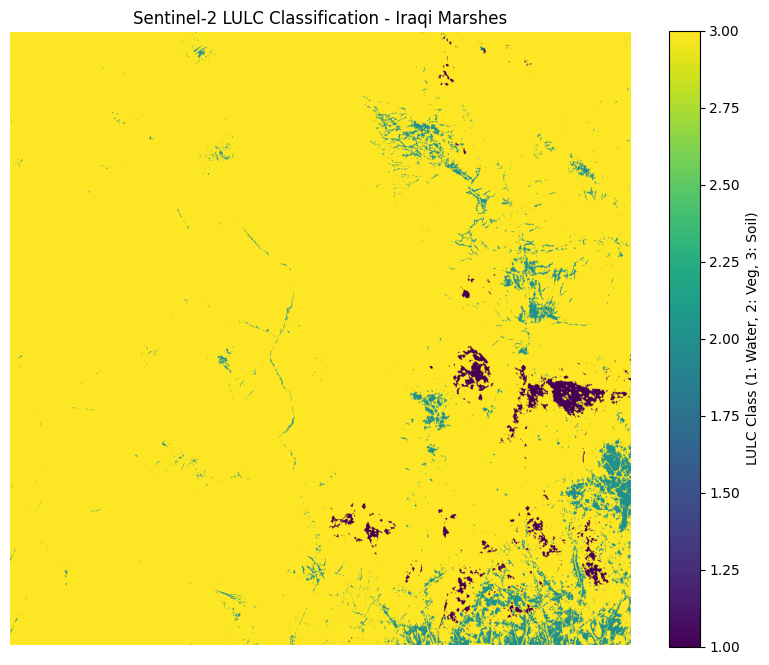

Pipeline execution completed successfully.


In [3]:
import pystac_client
import rasterio
from rasterio.windows import from_bounds
from rasterio.warp import transform_bounds
from rasterio.enums import Resampling
import numpy as np
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt

print("1. Connecting to STAC catalog...")
catalog = pystac_client.Client.open("https://earth-search.aws.element84.com/v1")
bbox_marshes = [46.85, 30.98, 47.05, 31.15]

search = catalog.search(
    collections=["sentinel-2-c1-l2a"],
    bbox=bbox_marshes,
    datetime="2024-05-01/2024-09-30",
    query={"eo:cloud_cover": {"lt": 5}}
)

items = list(search.items())

if len(items) == 0:
    raise ValueError("No satellite scenes found matching the criteria.")

print(f"Found {len(items)} scene(s). Selecting item: {items[0].id}")
item = items[0]

def get_band_url(item, possible_keys):
    for key in possible_keys:
        if key in item.assets:
            return item.assets[key].href
    raise KeyError(f"Key not found: {possible_keys}")

env = rasterio.Env(
    AWS_NO_SIGN_REQUEST='YES',
    GDAL_DISABLE_READDIR_BEFORE_FLUSH='YES',
    CPL_VSIL_CURL_ALLOWED_EXTENSIONS='.tif, .tiff',
    GDAL_HTTP_TIMEOUT=30
)

def read_band(possible_keys, bbox, target_shape=None):
    url = get_band_url(item, possible_keys)
    with env:
        with rasterio.open(url) as src:
            left, bottom, right, top = transform_bounds('EPSG:4326', src.crs, *bbox)
            window = from_bounds(left, bottom, right, top, transform=src.transform).round_shape()

            if target_shape is not None:
                band = src.read(1, window=window, out_shape=target_shape, resampling=Resampling.bilinear).astype(np.float32)
            else:
                band = src.read(1, window=window).astype(np.float32)

            transform = src.window_transform(window)
            profile = src.profile.copy()
            profile.update({
                'height': band.shape[0],
                'width': band.shape[1],
                'transform': transform,
                'driver': 'GTiff'
            })
    return band, profile

print("2. Fetching Blue band (B02)...")
b2, profile = read_band(['blue', 'b02', 'B02'], bbox_marshes)
target_shape = b2.shape

print("3. Fetching remaining spectral bands (B03, B04, B08, B11)...")
b3, _ = read_band(['green', 'b03', 'B03'], bbox_marshes, target_shape=target_shape)
b4, _ = read_band(['red', 'b04', 'B04'], bbox_marshes, target_shape=target_shape)
b8, _ = read_band(['nir', 'b08', 'B08'], bbox_marshes, target_shape=target_shape)
b11, _ = read_band(['swir16', 'b11', 'B11'], bbox_marshes, target_shape=target_shape)

print("4. Calculating NDVI & MNDWI spectral indices...")
np.seterr(divide='ignore', invalid='ignore')

ndvi = np.where((b8 + b4) == 0, 0, (b8 - b4) / (b8 + b4))
mndwi = np.where((b3 + b11) == 0, 0, (b3 - b11) / (b3 + b11))

ndvi = np.nan_to_num(ndvi, nan=0.0, posinf=0.0, neginf=0.0)
mndwi = np.nan_to_num(mndwi, nan=0.0, posinf=0.0, neginf=0.0)

feature_stack = np.stack([b2, b3, b4, b8, b11, ndvi, mndwi], axis=-1)

print("5. Training Random Forest classifier...")
height, width, num_bands = feature_stack.shape
X = feature_stack.reshape(-1, num_bands)

labels = np.zeros(X.shape[0], dtype=np.uint8)

water_mask = X[:, 6] > 0.1
veg_mask = (X[:, 5] > 0.2) & (~water_mask)
soil_mask = (~water_mask) & (~veg_mask)

labels[water_mask] = 1
labels[veg_mask] = 2
labels[soil_mask] = 3

model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
model.fit(X, labels)

classified_1d = model.predict(X)
classified_2d = classified_1d.reshape(height, width)

profile.update({
    'count': 1,
    'dtype': 'uint8',
    'nodata': 0
})

print("6. Exporting GeoTIFF and displaying results...")
with rasterio.open('marsh_lulc_classification.tif', 'w', **profile) as dst:
    dst.write(classified_2d.astype(np.uint8), 1)

plt.figure(figsize=(10, 8))
plt.imshow(classified_2d, cmap='viridis')
plt.colorbar(label='LULC Class (1: Water, 2: Veg, 3: Soil)')
plt.title('Sentinel-2 LULC Classification - Iraqi Marshes')
plt.axis('off')
plt.show()

print("Pipeline execution completed successfully.")